In [ ]:
#Imports
from pathlib import Path
from PIL import Image
from torchvision import datasets, transforms
import shutil
import random
import numpy as np
from torchvision.transforms import functional as TF
import random
from PIL import ImageOps

In [78]:
#Settings
RANDOM_SEED = 42
IMAGE_SIZE = 224

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

In [ ]:
# Paths

PROJECT_DIR = Path.cwd()

data_path = (
    PROJECT_DIR
    / "dataset"
    / "tom_and_jerry"
    / "tom_and_jerry"
)

# Processed datasets will be saved here
output_path = PROJECT_DIR / "processed_data"

assert data_path.exists(), (
    f"Dataset not found at: {data_path}"
)

print("Project directory:", PROJECT_DIR)
print("Dataset found:", data_path)
print("Output directory:", output_path)

Project directory: d:\Block14\AI\Project\EoinClaw.ai
Dataset found: d:\Block14\AI\Project\EoinClaw.ai\dataset\TomJerry\tom_and_jerry\tom_and_jerry
Output directory: d:\Block14\AI\Project\EoinClaw.ai\processed_data


In [80]:
#Load dataset
dataset = datasets.ImageFolder(root=data_path)

classes = dataset.classes
labels = dataset.targets

print("\nClasses:", classes)
print("Total images:", len(dataset))


Classes: ['jerry', 'tom', 'tom_jerry_0', 'tom_jerry_1']
Total images: 5478


In [81]:
# ============================================================
# TEMPORAL TRAIN / VALIDATION / TEST SPLIT
# 25% train / 25% validation / 50% test
# ============================================================

import re


def get_frame_number(path):
    """
    Extract frame number from filenames such as:
    frame18.jpg -> 18
    frame204.jpg -> 204
    """
    match = re.search(r"frame(\d+)", Path(path).stem)

    if match:
        return int(match.group(1))

    return 0


train_indices = []
val_indices = []
test_indices = []


# Split EACH CLASS separately
for class_index, class_name in enumerate(classes):

    # Get all dataset indices belonging to this class
    class_indices = [
        i
        for i, (_, label) in enumerate(dataset.samples)
        if label == class_index
    ]

    # Sort according to frame number
    class_indices.sort(
        key=lambda i: get_frame_number(dataset.samples[i][0])
    )

    n = len(class_indices)

    # 25% train
    train_end = int(n * 0.25)

    # Next 25% validation
    val_end = int(n * 0.50)

    # First 25%
    train_indices.extend(
        class_indices[:train_end]
    )

    # 25% - 50%
    val_indices.extend(
        class_indices[train_end:val_end]
    )

    # Final 50%
    test_indices.extend(
        class_indices[val_end:]
    )


print("\nDATA SPLIT")
print("============================")

print(f"Training:   {len(train_indices)}")
print(f"Validation: {len(val_indices)}")
print(f"Test:       {len(test_indices)}")


DATA SPLIT
Training:   1369
Validation: 1370
Test:       2739


In [82]:
#Preprocessing & augementation
regular_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE) #resize all images to 224 x 224
    )

])


# ============================================================
# 6. AUGMENTATION
# ============================================================
augmentation_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomApply([
        transforms.RandomRotation(15)
    ], p=0.7),

    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.2
        )
    ], p=0.7),

    transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE) #resize all images to 224 x 224
    )
])

In [83]:
#Create output dirs
for experiment in ["regular", "augmented"]:

    for split in ["train", "val", "test"]:

        for class_name in classes:

            folder = (
                output_path
                / experiment
                / split
                / class_name
            )

            folder.mkdir(
                parents=True,
                exist_ok=True
            )

In [84]:
def save_image(image, destination):

    #Ensure all images are RGB
    image = image.convert("RGB")

    #Resize to standard size
    image = regular_transform(image)

    image.save(
        destination,
        format="JPEG",
        quality=95
    )

#SAVE ORIGINAL DATASETS
def save_split(indices, split_name):

    print(f"Saving {split_name}: {len(indices)} images")

    for idx in indices:

        #Get image information
        image_path, class_index = dataset.samples[idx]
        class_name = classes[class_index]

        #Open and preprocess
        image = Image.open(image_path).convert("RGB")
        image = regular_transform(image)

        #Filename
        filename = f"{idx:06d}.jpg"

        #REGULAR DATASET
        regular_folder = (
            output_path
            / "regular"
            / split_name
            / class_name
        )

        regular_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        regular_destination = (
            regular_folder / filename
        )

        image.save(
            regular_destination,
            format="JPEG",
            quality=95
        )

        #AUGMENTED DATASET
        augmented_folder = (
            output_path
            / "augmented"
            / split_name
            / class_name
        )

        augmented_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        augmented_destination = (
            augmented_folder / filename
        )

        image.save(
            augmented_destination,
            format="JPEG",
            quality=95
        )



save_split(train_indices, "train")
save_split(val_indices, "val")
save_split(test_indices, "test")

print("\nOriginal datasets saved successfully.")

Saving train: 1369 images
Saving val: 1370 images
Saving test: 2739 images

Original datasets saved successfully.


In [85]:
#Add augmented dataset
print("Creating augmented training images...")


for count, idx in enumerate(train_indices):

    image_path, class_index = dataset.samples[idx]

    class_name = classes[class_index]

    image = Image.open(
        image_path
    ).convert("RGB")

    #Apply random augmentation
    augmented_image = augmentation_transform(image)

    #Resize to ensure 224 x 224
    augmented_image = regular_transform(
        augmented_image
    )

    #Give augmented image different filename
    filename = f"{idx:06d}_aug.jpg"

    destination = (
        output_path
        / "augmented"
        / "train"
        / class_name
        / filename
    )

    augmented_image.save(
        destination,
        format="JPEG",
        quality=95
    )


Creating augmented training images...


In [86]:
#Count dataset
def count_images(folder):

    return len(
        list(folder.rglob("*.jpg"))
    )


print("\n====================================")
print("FINISHED")
print("====================================")


print("\nREGULAR DATASET")

print(
    "Train:",
    count_images(
        output_path / "regular" / "train"
    )
)

print(
    "Validation:",
    count_images(
        output_path / "regular" / "val"
    )
)

print(
    "Test:",
    count_images(
        output_path / "regular" / "test"
    )
)


print("\nAUGMENTED DATASET")

print(
    "Train:",
    count_images(
        output_path / "augmented" / "train"
    )
)

print(
    "Validation:",
    count_images(
        output_path / "augmented" / "val"
    )
)

print(
    "Test:",
    count_images(
        output_path / "augmented" / "test"
    )
)


print("\nSaved to:")
print(output_path)


FINISHED

REGULAR DATASET
Train: 1369
Validation: 1370
Test: 2739

AUGMENTED DATASET
Train: 2738
Validation: 1370
Test: 2739

Saved to:
d:\Block14\AI\Project\EoinClaw.ai\processed_data


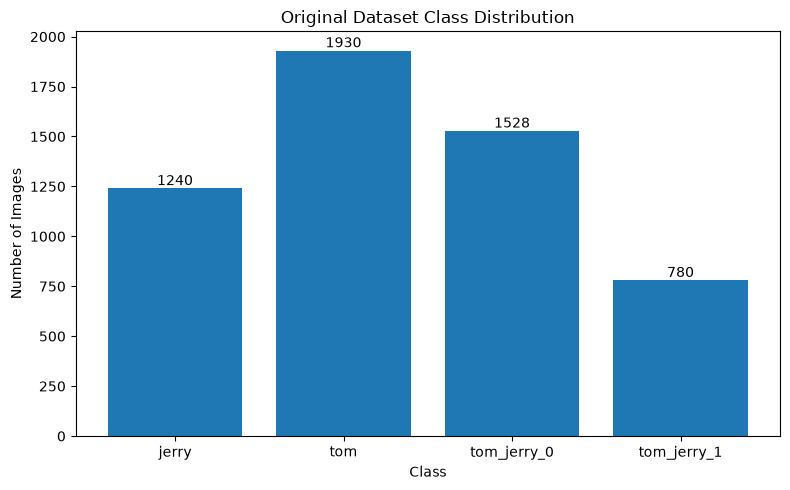

In [87]:
# ============================================================
# DATA VISUALISATION 1
# Original class distribution
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

class_counts = Counter(dataset.targets)

class_names = [
    classes[i] for i in class_counts.keys()
]

counts = list(class_counts.values())

plt.figure(figsize=(8, 5))

bars = plt.bar(class_names, counts)

plt.title("Original Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

# Add number above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

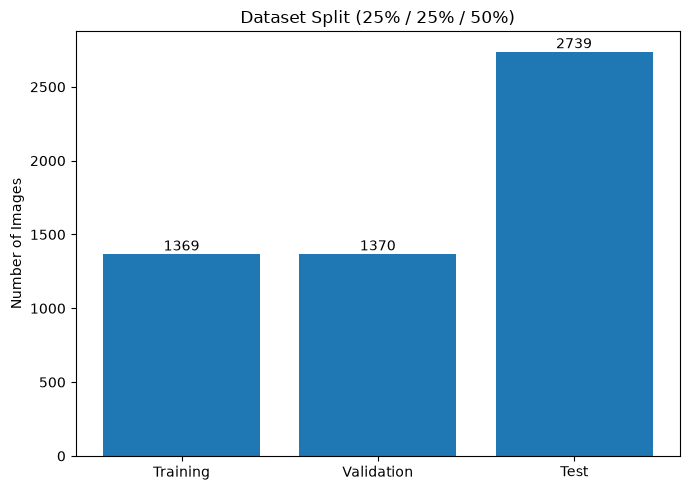

In [88]:
# ============================================================
# DATA VISUALISATION 2
# Train / Validation / Test Split
# ============================================================

split_names = ["Training", "Validation", "Test"]

split_counts = [
    len(train_indices),
    len(val_indices),
    len(test_indices)
]

plt.figure(figsize=(7, 5))

bars = plt.bar(split_names, split_counts)

plt.title("Dataset Split (25% / 25% / 50%)")
plt.ylabel("Number of Images")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

         Class  Training  Validation  Test
0        jerry       310         310   620
1          tom       482         483   965
2  tom_jerry_0       382         382   764
3  tom_jerry_1       195         195   390


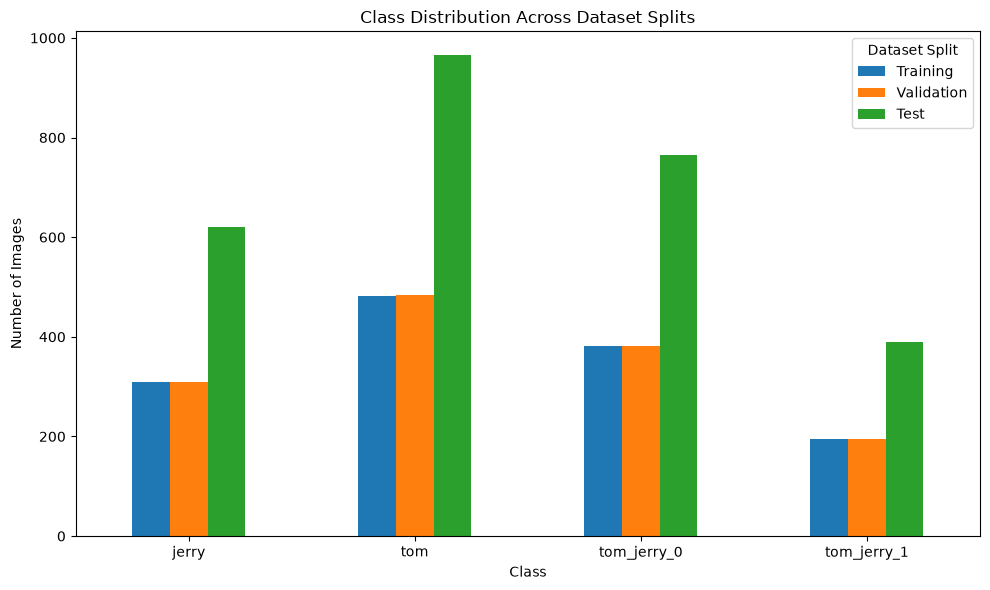

In [89]:
# ============================================================
# DATA VISUALISATION 3
# Class distribution within each split
# ============================================================

def get_class_counts(indices):

    split_labels = [
        labels[i] for i in indices
    ]

    counts = Counter(split_labels)

    return [
        counts[i] for i in range(len(classes))
    ]


train_counts = get_class_counts(train_indices)
val_counts = get_class_counts(val_indices)
test_counts = get_class_counts(test_indices)


distribution_df = pd.DataFrame({
    "Class": classes,
    "Training": train_counts,
    "Validation": val_counts,
    "Test": test_counts
})

print(distribution_df)


# Plot
distribution_df.set_index("Class").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=0)
plt.legend(title="Dataset Split")

plt.tight_layout()
plt.show()

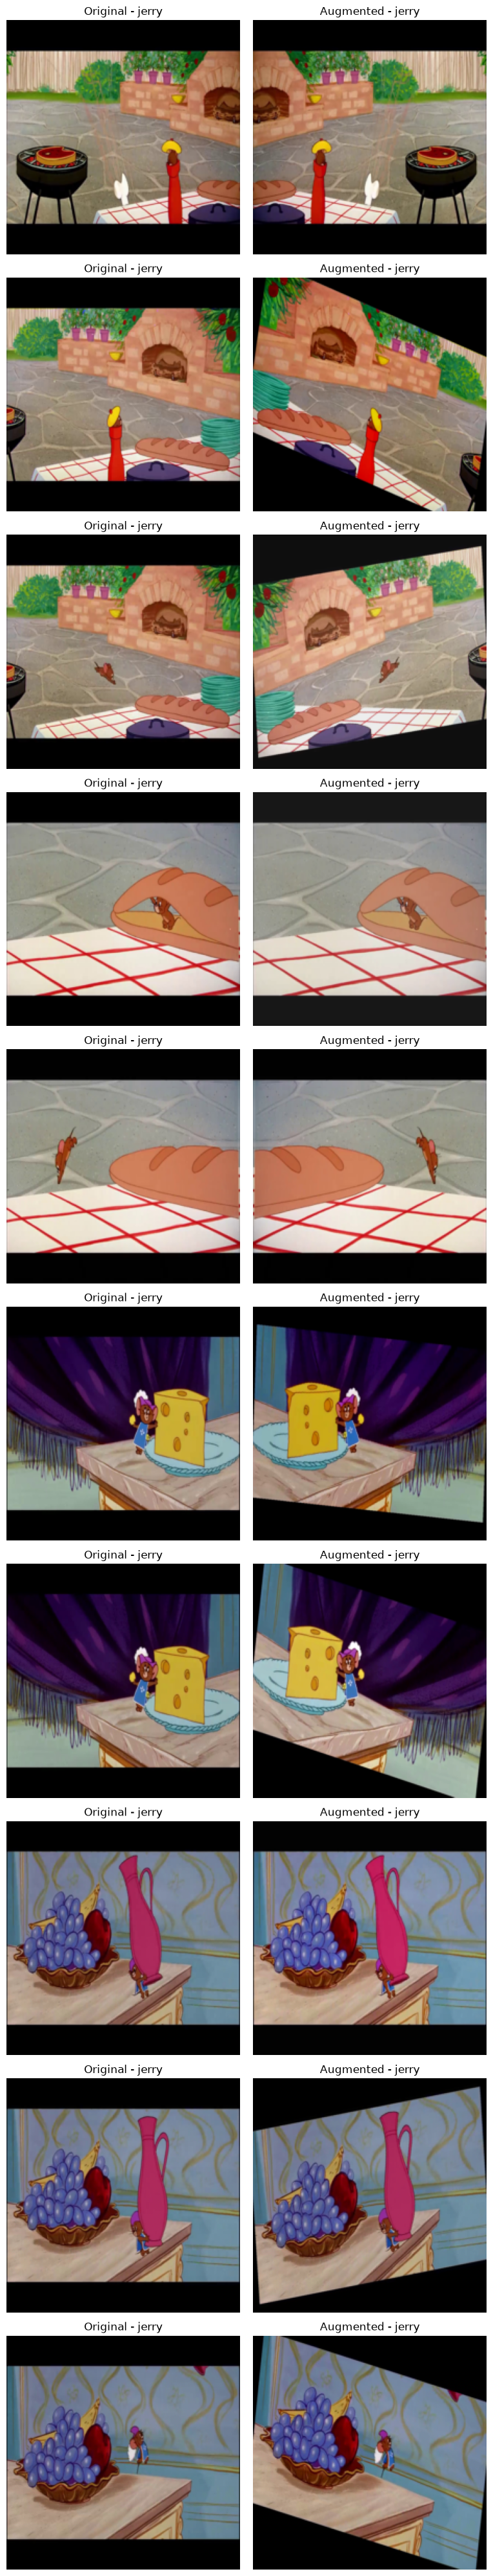

In [92]:
# ============================================================
# DATA VISUALISATION 4
# Original vs Augmented Examples
# ============================================================

NUM_EXAMPLES = 10

fig, axes = plt.subplots(
    NUM_EXAMPLES,
    2,
    figsize=(8, 4 * NUM_EXAMPLES)
)

for row in range(NUM_EXAMPLES):

    # Select training image
    idx = train_indices[row]

    image_path, class_index = dataset.samples[idx]

    # Open original
    original = Image.open(image_path).convert("RGB")

    # Regular preprocessing
    original_processed = regular_transform(original)

    # Create augmented version
    augmented = augmentation_transform(original)

    # Display original
    axes[row, 0].imshow(original_processed)

    axes[row, 0].set_title(
        f"Original - {classes[class_index]}"
    )

    axes[row, 0].axis("off")


    # Display augmented
    axes[row, 1].imshow(augmented)

    axes[row, 1].set_title(
        f"Augmented - {classes[class_index]}"
    )

    axes[row, 1].axis("off")


plt.tight_layout()
plt.show()

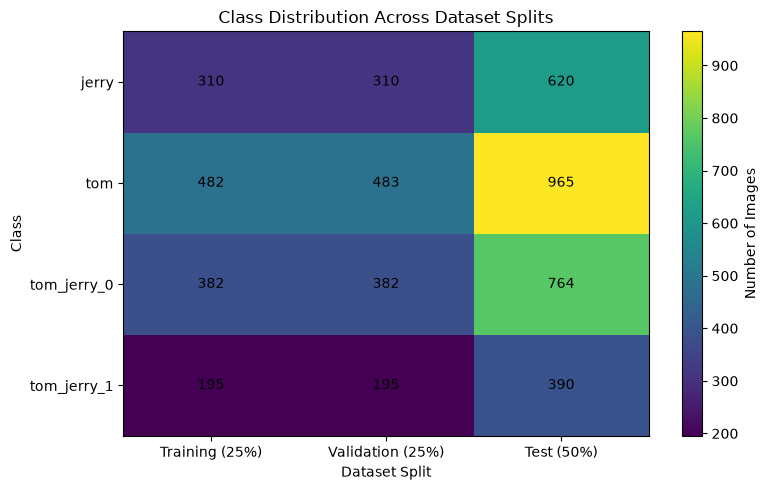

In [91]:
# ============================================================
# DATA VISUALISATION
# Class Distribution Heatmap
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

#Rows = classes
#Columns = dataset splits
heatmap_data = np.array([
    train_counts,
    val_counts,
    test_counts
]).T

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(heatmap_data, aspect="auto")

#Axis labels
ax.set_xticks(range(3))
ax.set_xticklabels([
    "Training (25%)",
    "Validation (25%)",
    "Test (50%)"
])

ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes)

#Put actual image count inside each cell
for i in range(len(classes)):
    for j in range(3):
        ax.text(
            j,
            i,
            heatmap_data[i, j],
            ha="center",
            va="center"
        )

ax.set_title("Class Distribution Across Dataset Splits")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Class")

plt.colorbar(
    im,
    ax=ax,
    label="Number of Images"
)

plt.tight_layout()
plt.show()